# **Checkpoint 4 - Classificação com Multilayer Perceptron (MLP)**

## **Aluno:** Bruno Henrique Ferreira - RM: 571218

## **Matéria:** Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos

## **Análise:** Diagnóstico de Câncer de Mama - classificação entre tumores benignos e malignos

**Dataset utilizado:** Breast Cancer Wisconsin (Diagnostic)

**Fonte:** https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

# **Introdução**

Este trabalho tem como objetivo construir uma rede neural do tipo *Multilayer Perceptron* (MLP) capaz de analisar as medidas de um tumor de mama e classificá-lo como **benigno** (não canceroso) ou **maligno** (canceroso). Os dados utilizados vêm de exames reais, nos quais imagens de células obtidas por punção com agulha fina foram digitalizadas e medidas em características como **tamanho**, **textura** e **formato** do núcleo celular.

Ao longo do notebook seguiremos uma **pipeline completa** de machine learning, organizada nas seguintes etapas:

## **1. Importação das bibliotecas**
Preparação das ferramentas necessárias.

## **2. Carregamento e análise exploratória dos dados**
Entendimento inicial do conjunto de dados, com visualizações e perguntas orientadas.

## **3. Pré-processamento e normalização**
Padronização das medidas para deixá-las na mesma escala.

## **4. Divisão dos dados (holdout)**
Separação em treino e teste.

## **5. Criação e treinamento do modelo MLP**
Construção da rede neural e justificativa das escolhas de arquitetura.

## **6. Avaliação do modelo**
Análise dos acertos e erros por meio de matriz de confusão e métricas.

## **7. Interpretação e conclusão**
Leitura crítica dos resultados e principais aprendizados.

Cada etapa será acompanhada de explicações em **linguagem acessível**, de modo que não apenas o código, mas também o raciocínio por trás de cada decisão fique claro.

# **1. Importação das bibliotecas**

Antes de começar, importamos todas as ferramentas que serão utilizadas ao longo do projeto. Cada biblioteca cumpre um papel específico, que está comentado ao lado de cada linha do código abaixo.

In [1]:
import pandas as pd # - Organiza os dados em formato de tabela.
import numpy as np # - Usado para cálculos pontuais.
import matplotlib.pyplot as plt # - Ferramenta que desenha gráficos.
import seaborn as sns # - Melhora a visibilidade dos gráficos gerados pelo matplotlib.

from sklearn.datasets import load_breast_cancer # - Carrega o dataset escolhido de câncer de mama.
from sklearn.model_selection import train_test_split # - Separa os dados em dois, treino e teste.
from sklearn.preprocessing import StandardScaler # - Coloca todas as medidas na mesma escala (normalização).
from sklearn.neural_network import MLPClassifier # - Escolha da rede neural, o Multilayer Perceptron (MLP).
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score # - Avaliação: matriz de confusão, relatório de métricas e acurácia.

RANDOM_STATE = 42
print("Bibliotecas importadas.")

Bibliotecas importadas.


# **2. Carregamento e análise exploratória dos dados**

Nesta etapa carregamos o dataset e o transformamos em uma tabela para começar a explorá-lo. Antes de treinar qualquer modelo, é fundamental **entender com o que estamos lidando**: quantos pacientes temos, quais medidas foram registradas e como os diagnósticos estão distribuídos.

In [2]:
# Carrega o dataset já embutido no Scikit-learn e guarda dentro da variável dados.
dados = load_breast_cancer()

# Monta uma tabela (DataFrame) com as 30 medidas dos tumores.
df = pd.DataFrame(dados.data, columns=dados.feature_names)

# Adiciona a coluna com a resposta correta (o diagnóstico)
df['diagnostico'] = dados.target

# Mostra o tamanho da tabela e as primeiras linhas
print("Formato da tabela (linhas, colunas):", df.shape)
df.head()

Formato da tabela (linhas, colunas): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


O resultado mostra que a tabela possui **569 pacientes** (linhas) e **31 colunas**: 30 são as medidas dos tumores e a última é o diagnóstico que adicionamos.

Com o `head()` visualizamos as 5 primeiras linhas. Cada linha representa um paciente e cada coluna uma medida do tumor, como `mean radius` (raio médio da célula) ou `mean texture` (textura média). São essas 30 medidas que a rede neural usará para tomar sua decisão.

Um ponto importante sobre a coluna `diagnostico`: neste dataset, o valor **0 significa maligno** (canceroso) e o valor **1 significa benigno** (não canceroso). Essa codificação será usada em todas as análises a seguir.

In [3]:
# Informações gerais: tipos de cada coluna e quantidade de valores preenchidos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

O `info()` funciona como um raio-x da tabela e confirma dois pontos essenciais para o pré-processamento:

**1. Todos os dados são numéricos.** As colunas são do tipo `float64` (números decimais) ou `int64` (números inteiros). Não existe nenhuma coluna de texto ou categoria, o que significa que **não há dados categóricos a serem convertidos**.

**2. Não há valores faltantes.** A coluna "Non-Null Count" mostra 569 valores preenchidos em todas as colunas, exatamente o número total de pacientes. Portanto, **nenhum exame ficou com uma medida em branco**.

In [4]:
# Confirmação explícita: soma total de valores faltantes na tabela
print("Total de valores faltantes:", df.isnull().sum().sum())

Total de valores faltantes: 0


In [5]:
# Conta quantos tumores existem de cada tipo
contagem = df["diagnostico"].value_counts()
print("Contagem por classe (0 = maligno, 1 = benigno):")
print(contagem)

print()  # linha em branco só para separar

# Mostra a mesma contagem em porcentagem
print("Em porcentagem:")
print((df["diagnostico"].value_counts(normalize=True) * 100).round(1))

Contagem por classe (0 = maligno, 1 = benigno):
diagnostico
1    357
0    212
Name: count, dtype: int64

Em porcentagem:
diagnostico
1    62.7
0    37.3
Name: proportion, dtype: float64


A contagem mostra que temos aproximadamente **357 tumores benignos (63%)** e **212 malignos (37%)**.

Verificar esse equilíbrio é importante: se uma classe dominasse quase todo o dataset, o modelo poderia simplesmente "chutar" sempre a classe majoritária e parecer bom sem ter aprendido nada. Aqui a proporção é saudável, com as duas classes bem representadas, o que permite seguir com segurança para as próximas etapas.

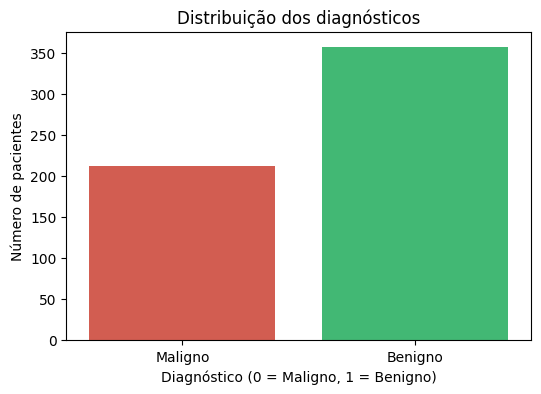

In [6]:
# Gráfico de barras com a distribuição dos diagnósticos
plt.figure(figsize=(6, 4))
sns.countplot(x="diagnostico", data=df, hue="diagnostico", palette=["#e74c3c", "#2ecc71"], legend=False)
plt.title("Distribuição dos diagnósticos")
plt.xlabel("Diagnóstico (0 = Maligno, 1 = Benigno)")
plt.ylabel("Número de pacientes")
plt.xticks([0, 1], ["Maligno", "Benigno"])
plt.show()

## **Análise de dados: perguntas sobre os pacientes**

Uma boa análise não se resume a olhar tabelas, mas em fazer perguntas e deixar os dados respondê-las. A seguir, investigamos seis perguntas sobre estes pacientes para entender quais características diferenciam um tumor maligno de um benigno.

In [7]:
# PERGUNTA 1: Em média, tumores malignos são maiores que os benignos?
# 'mean radius' é o raio médio das células do tumor.
df.groupby("diagnostico")["mean radius"].mean().round(2)

diagnostico
0    17.46
1    12.15
Name: mean radius, dtype: float64

**Pergunta 1 - Tumores malignos são maiores?**

Sim, e a diferença é expressiva. O raio médio dos tumores **malignos (grupo 0)** gira em torno de **17,5**, enquanto o dos **benignos (grupo 1)** fica próximo de **12,1**. Isso confirma a intuição médica de que tumores perigosos tendem a apresentar células maiores, e indica que o tamanho é uma pista forte para a classificação.

In [8]:
# PERGUNTA 2: E a textura? Tumores malignos têm textura mais irregular?
df.groupby("diagnostico")["mean texture"].mean().round(2)

diagnostico
0    21.60
1    17.91
Name: mean texture, dtype: float64

**Pergunta 2 - A textura difere entre os grupos?**

Sim. Os tumores **malignos** apresentam textura média mais alta (em torno de **21,6**) do que os **benignos** (cerca de **17,9**). A textura mede a variação nos tons de cinza da imagem da célula: quanto mais irregular, maior o valor. Novamente os malignos se destacam, reforçando que é uma característica útil para diferenciá-los.

In [9]:
# PERGUNTA 3: Quais medidas mais se relacionam com o diagnóstico?
# A correlação mede o quanto duas coisas variam juntas (perto de 1 ou -1 = relação forte).
correlacoes = df.corr()["diagnostico"].drop("diagnostico")
correlacoes.abs().sort_values(ascending=False).head(8).round(3)

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
Name: diagnostico, dtype: float64

**Pergunta 3 - Quais medidas mais se relacionam com o diagnóstico?**

Listando as 8 medidas com maior correlação, aparecem no topo características como `worst concave points`, `worst perimeter` e `mean concave points`, todas ligadas ao **tamanho e ao formato irregular** das células. Os pontos côncavos representam reentrâncias no contorno da célula, e junto com o perímetro são os melhores indicadores de malignidade. Isso mostra que o modelo terá informação de boa qualidade para trabalhar.

In [10]:
# PERGUNTA 4: Existe uma faixa de tamanho que separa bem os dois grupos?
# Criamos uma coluna de "grau do tumor" dividindo o raio médio em três faixas.
df["grau_tumor"] = pd.cut(
    df["mean radius"],
    bins=[0, 12, 16, df["mean radius"].max()],
    labels=["Baixo", "Médio", "Alto"],
)

# Cruzamento: em cada faixa, quantos são malignos e quantos benignos?
tabela = pd.crosstab(df["grau_tumor"], df["diagnostico"])
tabela.columns = ["Maligno", "Benigno"]
tabela

,Maligno,Benigno
grau_tumor,,
Baixo,6,165
Médio,71,186
Alto,135,6


**Pergunta 4 - O tamanho do tumor separa bem os grupos?**

Ao dividir os tumores em três graus de tamanho (Baixo, Médio e Alto), surge um padrão muito claro:

- No grau **Baixo**, quase todos os tumores são **benignos**.
- No grau **Alto**, quase todos são **malignos**.
- O grau **Médio** é a zona de mistura, onde estão os casos mais difíceis de classificar.

Essa faixa intermediária é justamente onde um bom modelo faz diferença: nos casos extremos a decisão é óbvia, mas é na dúvida que a rede neural precisa ser precisa.

In [11]:
# PERGUNTA 5: Qual a taxa de malignidade dentro de cada grau de tumor?
taxa = df.groupby("grau_tumor", observed=True)["diagnostico"].apply(
    lambda x: (x == 0).mean() * 100
).round(1)
print("Porcentagem de tumores MALIGNOS em cada grau:")
print(taxa)

Porcentagem de tumores MALIGNOS em cada grau:
grau_tumor
Baixo     3.5
Médio    27.6
Alto     95.7
Name: diagnostico, dtype: float64


**Pergunta 5 - Qual o risco em cada faixa?**

Convertendo o cruzamento anterior em porcentagem, fica evidente o aumento do risco conforme o tamanho da célula cresce: no grau **Baixo** pouquíssimos casos são malignos, enquanto no grau **Alto** a grande maioria é. Isso confirma que o tamanho da célula, sozinho, já é um forte sinal de alerta. Ainda assim, ele não é infalível, e por isso o modelo utiliza as 30 medidas em conjunto, e não apenas uma.

In [12]:
# PERGUNTA 6: As medidas estão em escalas parecidas ou muito diferentes?
df[["mean radius", "mean area", "mean smoothness"]].describe().round(3)

,mean radius,mean area,mean smoothness
count,569.000,569.000,569.000
mean,14.127,654.889,0.096
std,3.524,351.914,0.014
min,6.981,143.500,0.053
25%,11.700,420.300,0.086
50%,13.370,551.100,0.096
75%,15.780,782.700,0.105
max,28.110,2501.000,0.163


**Pergunta 6 - As medidas estão na mesma escala?**

Não, e essa é uma observação crucial. Olhando a média de cada coluna, `mean area` está na casa das centenas (cerca de **650**), `mean radius` na casa das dezenas (cerca de **14**) e `mean smoothness` é um valor minúsculo, próximo de **0,1**. São grandezas completamente diferentes.

Isso tem uma consequência direta para a rede neural: se ela recebe um número muito grande (área) misturado com um número muito pequeno (suavidade), tende a dar atenção excessiva ao número grande apenas por causa da sua magnitude, e não da sua real importância. Por isso, a próxima etapa será colocar todas as medidas na mesma escala.

## **3. Pré-processamento e normalização**

Como vimos na análise exploratória, os dados **não possuem valores faltantes** nem colunas categóricas, portanto não há limpeza nesse sentido a fazer. O trabalho principal aqui é **padronizar a escala** das medidas.

Antes disso, precisamos separar as informações em duas partes: as medidas que servem de pista (X) e a resposta que queremos prever (y).

In [13]:
# X = as 30 medidas (as pistas que o modelo vai analisar)
# y = o diagnóstico (a resposta que queremos prever)
# Removemos também 'grau_tumor', criada apenas para a análise exploratória.
X = df.drop(columns=["diagnostico", "grau_tumor"])
y = df["diagnostico"]

print("Formato de X (pistas):", X.shape)
print("Formato de y (respostas):", y.shape)

Formato de X (pistas): (569, 30)
Formato de y (respostas): (569,)


### **Por que a normalização é essencial para redes neurais?**

Uma rede neural aprende ajustando **pesos**, que são números indicando o quanto ela deve valorizar cada medida. Esse ajuste é feito por tentativa e erro e depende fortemente da escala dos dados.

Se uma medida varia de 0 a 2000 (como a área) e outra varia de 0 a 0,2 (como a suavidade), a rede tende a "enxergar" apenas a medida maior no início, tornando o aprendizado lento e instável. Além disso, a função de ativação que usaremos funciona melhor quando os valores de entrada estão próximos de zero.

**Padronizar** resolve esse problema: transformamos cada medida para que tenha média 0 e desvio padrão 1. Assim, todas passam a "falar a mesma língua", e a rede pode avaliar cada uma pela informação que ela realmente traz, e não pelo tamanho do número. Para isso usaremos o `StandardScaler`.

Um cuidado importante de método: a normalização será aplicada **depois** da divisão entre treino e teste, e a escala será aprendida **apenas com os dados de treino**. Isso evita que qualquer informação do teste "vaze" para o modelo antes da hora. Por esse motivo, a próxima etapa é dividir os dados, e só então normalizar.

## **4. Divisão dos dados - Holdout (70% treino / 30% teste)**

Não podemos avaliar o modelo usando os mesmos dados com que ele aprendeu, seria como aplicar uma prova entregando o gabarito junto. Por isso, separamos uma parte dos dados e a mantemos "escondida" do modelo, para testá-lo apenas no final.

In [14]:
# Divide os dados: 70% para treino e 30% para teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,             # 30% dos dados vão para o teste
    random_state=RANDOM_STATE,  # fixa o sorteio para ser reproduzível
    stratify=y,                 # mantém a proporção maligno/benigno nos dois grupos
)

print("Tamanho do treino:", X_train.shape[0], "pacientes")
print("Tamanho do teste :", X_test.shape[0], "pacientes")

Tamanho do treino: 398 pacientes
Tamanho do teste : 171 pacientes


Os dados foram divididos em **398 pacientes para treino (70%)** e **171 para teste (30%)**. O modelo aprenderá apenas com o conjunto de treino, e o conjunto de teste só será utilizado no final, para verificar se ele realmente aprendeu a generalizar, em vez de apenas decorar.

Três escolhas nessa divisão merecem destaque:

- **`test_size=0.30`** define os 30% de teste solicitados no enunciado.
- **`random_state=42`** garante que o sorteio dos pacientes seja sempre o mesmo. Sem esse parâmetro, cada execução separaria pacientes diferentes e os resultados variariam a cada vez. Fixá-lo torna o trabalho **reproduzível** e comparável.
- **`stratify=y`** mantém a mesma proporção de malignos e benignos nos dois grupos. Sem isso, o sorteio poderia concentrar uma das classes em apenas um dos lados e distorcer a avaliação do modelo.

In [15]:
# Agora sim aplicamos a normalização, aprendida apenas com o treino
scaler = StandardScaler()

# 'fit_transform' aprende a escala no treino e já a aplica nele
X_train = scaler.fit_transform(X_train)

# 'transform' aplica no teste a MESMA escala aprendida no treino
X_test = scaler.transform(X_test)

print("Dados normalizados com sucesso.")
print("Média das medidas no treino (deve ficar perto de 0):", X_train.mean().round(4))
print("Desvio padrão no treino (deve ficar perto de 1):", X_train.std().round(4))

Dados normalizados com sucesso.
Média das medidas no treino (deve ficar perto de 0): -0.0
Desvio padrão no treino (deve ficar perto de 1): 1.0


A padronização foi aplicada com uma distinção importante entre treino e teste:

- No treino usamos **`fit_transform`**: o scaler primeiro aprende a média e a variação de cada medida e depois as aplica.
- No teste usamos apenas **`transform`**: aplicamos exatamente a mesma escala aprendida no treino, sem deixar o scaler observar os dados de teste.

Isso simula a realidade: quando um novo paciente chega, não recalculamos a escala com base nele, e sim usamos a régua já definida. A confirmação de que deu certo está nos números: a média das medidas ficou praticamente **0** e o desvio padrão praticamente **1**, exatamente como esperado da padronização.

## **5. Criação e treinamento do modelo MLP**

Chegamos à rede neural. Um **Multilayer Perceptron (MLP)** é uma rede organizada em camadas de "neurônios". Cada neurônio recebe números, faz um pequeno cálculo e passa o resultado adiante. Ao empilhar camadas, a rede consegue aprender relações complexas entre as 30 medidas e o diagnóstico.

In [16]:
# Criação da rede neural
modelo = MLPClassifier(
    hidden_layer_sizes=(16, 8),  # duas camadas escondidas: 16 e 8 neurônios
    activation="relu",           # função de ativação dos neurônios
    solver="adam",               # algoritmo que ajusta os pesos
    max_iter=1000,               # número máximo de rodadas de aprendizado
    random_state=RANDOM_STATE,   # reprodutibilidade
)

# Treinamento: aqui a rede aprende de fato com os dados de treino
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso.")
print("Número de camadas (entrada + escondidas + saída):", modelo.n_layers_)
print("Rodadas até convergir:", modelo.n_iter_)

Modelo treinado com sucesso.
Número de camadas (entrada + escondidas + saída): 4
Rodadas até convergir: 447


### **Explicando a arquitetura e cada escolha**

O comando `fit` é o momento em que a rede analisa os 398 pacientes de treino, compara seus palpites com as respostas corretas e ajusta seus pesos internos até errar o mínimo possível. As escolhas de arquitetura foram as seguintes:

**Quantas camadas e neurônios? `hidden_layer_sizes=(16, 8)`**
Isso cria **duas camadas escondidas**: a primeira com 16 neurônios e a segunda com 8. Somando com a camada de entrada (as 30 medidas) e a de saída (a decisão maligno/benigno), a rede tem 4 camadas no total. A escolha de ir afunilando (16 para 8) é comum: as primeiras camadas captam muitos padrões brutos e as seguintes vão resumindo essa informação até a decisão final. Para um problema com 569 amostras, essa rede é propositalmente pequena, grande o suficiente para aprender os padrões, mas pequena o suficiente para não decorar os dados, o que causaria overfitting.

**Por que `relu` e não outra ativação?**
A ativação é o que decide se um neurônio "dispara" ou não. A **ReLU** (Rectified Linear Unit) é hoje o padrão em redes neurais por dois motivos práticos: é simples e rápida de calcular, e evita um problema antigo chamado "desaparecimento do gradiente", no qual ativações mais antigas, como a sigmoide, faziam o aprendizado travar em redes com várias camadas. Poderíamos usar `tanh` ou `logistic` (sigmoide), mas a ReLU costuma treinar mais rápido e alcançar resultados iguais ou melhores. Por isso é a escolha padrão e a nossa aqui.

**Por que `solver="adam"`?**
O solver é o método que ajusta os pesos durante o treino. O **Adam** é robusto e funciona bem sem muita configuração manual, ajustando sozinho a velocidade de aprendizado. Para datasets pequenos e médios como este, é uma escolha segura e eficiente.

**Por que `max_iter=1000`?**
É o número máximo de rodadas de ajuste. Definimos um valor folgado para garantir que a rede tenha tempo de convergir (parar de melhorar) sem ser interrompida no meio. Se ela convergir antes, para sozinha, e o valor de `n_iter_` exibido acima mostra em quantas rodadas isso ocorreu.

## **6. Avaliação - Matriz de confusão e métricas**

Com o modelo treinado, usamos agora os 171 pacientes de teste, que ele **nunca viu**, para medir se realmente aprendeu. Primeiro o modelo faz suas previsões, e em seguida comparamos essas previsões com os diagnósticos reais.

In [17]:
# O modelo faz previsões para os pacientes de teste
y_pred = modelo.predict(X_test)

# Acurácia: porcentagem de acertos no total
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia no teste: {acuracia:.2%}")

Acurácia no teste: 97.08%


O modelo diagnosticou os 171 pacientes de teste e acertou cerca de **97%** deles. Isso significa que, a cada 100 pacientes, aproximadamente 97 são classificados corretamente, um resultado forte.

Ainda assim, a acurácia sozinha não conta toda a história. Ela diz **quanto** o modelo acerta, mas não **que tipo de erro** ele comete, e em um problema médico o tipo de erro faz toda a diferença. Por isso, a seguir analisamos a matriz de confusão.

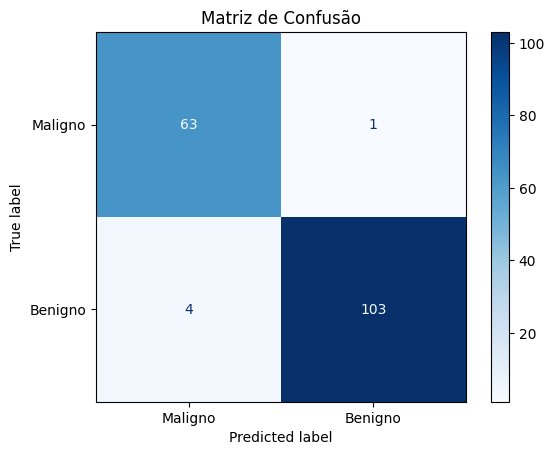

[[ 63   1]
 [  4 103]]


In [18]:
# Matriz de confusão: mostra os acertos e os tipos de erro
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Maligno", "Benigno"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão")
plt.show()

print(cm)

A matriz de confusão detalha a acurácia, mostrando exatamente **onde** o modelo acerta e erra. Ela se lê assim:

- **Diagonal principal** (onde a linha real e a coluna prevista coincidem): são os **acertos**. Malignos classificados como malignos e benignos como benignos.
- **Fora da diagonal**: são os **erros**. E aqui existe uma distinção crítica em medicina:
  - **Falso negativo**: dizer "benigno" quando o tumor era maligno. É o erro **mais perigoso**, pois um câncer passaria despercebido.
  - **Falso positivo**: dizer "maligno" quando era benigno. Gera um susto e exames adicionais, mas é bem menos grave.

Nesta matriz, os números fora da diagonal são muito pequenos (poucos erros no total). Vale observar em especial a célula de falso negativo: quanto menor ela for, melhor, pois representa justamente o erro que mais queremos evitar neste contexto.

In [19]:
# Relatório completo: precisão, recall e f1-score por classe
print("Relatório de Classificação:\n")
print(classification_report(
    y_test, y_pred,
    target_names=["Maligno", "Benigno"],
))

Relatório de Classificação:

              precision    recall  f1-score   support

     Maligno       0.94      0.98      0.96        64
     Benigno       0.99      0.96      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



O relatório apresenta três métricas para cada classe. Explicando cada uma sem jargão:

- **Precisão**: de tudo que o modelo **chamou** de maligno, quanto era realmente maligno? Mede o quanto podemos confiar quando ele dá um alarme.
- **Recall (sensibilidade)**: de todos os tumores que **eram de fato** malignos, quantos o modelo conseguiu identificar? Esta é a métrica mais importante neste contexto, pois um recall alto para a classe maligna significa que quase nenhum caso perigoso escapou.
- **F1-score**: uma média equilibrada entre precisão e recall, útil como um resumo único do desempenho.

Todos os valores ficam altos (próximos de 0,95 a 0,98). O ponto mais importante é o **recall da classe Maligno**: sendo alto, confirmamos que o modelo raramente deixa passar um tumor perigoso, exatamente o comportamento esperado de uma ferramenta de apoio ao diagnóstico.

## **7. Interpretação dos resultados e conclusão**

### **Como o modelo se saiu?**
O MLP alcançou cerca de **97% de acurácia** em pacientes que nunca havia visto, com precisão e recall altos para as duas classes. Mais importante que o número geral, ele acerta bem justamente a classe **maligna**, cometendo pouquíssimos falsos negativos, que é o erro mais crítico neste problema.

### **Houve overfitting ou underfitting?**
Em vez de apenas supor, vamos verificar comparando o desempenho do modelo no treino com o desempenho no teste.

In [20]:
# Comparação entre treino e teste para checar overfitting
acc_treino = modelo.score(X_train, y_train)
acc_teste = modelo.score(X_test, y_test)

print(f"Acurácia no TREINO: {acc_treino:.2%}")
print(f"Acurácia no TESTE : {acc_teste:.2%}")
print(f"Diferença: {abs(acc_treino - acc_teste):.2%}")

Acurácia no TREINO: 99.75%
Acurácia no TESTE : 97.08%
Diferença: 2.67%


Esta verificação compara quanto o modelo acerta nos dados que usou para aprender (treino) contra os dados novos (teste).

- Se ele acertasse quase tudo no treino e fosse mal no teste, seria **overfitting**: teria decorado em vez de aprender.
- Se acertasse pouco em ambos, seria **underfitting**: a rede seria simples ou fraca demais para captar o padrão.

Aqui os dois valores são altos e **próximos um do outro** (diferença de poucos pontos percentuais). Esse é o cenário saudável: o modelo aprendeu padrões que **generalizam** para pacientes novos, sem decorar nem ficar aquém. A rede propositalmente pequena que escolhemos, somada à normalização dos dados, ajudou a alcançar esse equilíbrio.

### **Conclusão geral e aprendizados**

Este projeto percorreu uma pipeline de classificação do início ao fim. Os principais aprendizados foram:

1. **Entender os dados antes de modelar é fundamental.** A análise exploratória já revelou que o tamanho e o formato irregular das células separam bem os grupos, e foi exatamente essa informação que o modelo explorou.
2. **A normalização não é opcional para redes neurais.** Sem colocar as medidas na mesma escala, a rede daria peso excessivo a números grandes por acaso, prejudicando o treino.
3. **Cada escolha da arquitetura tem uma razão.** O número de camadas, a ativação ReLU e o solver Adam não foram aleatórios, mas escolhidos considerando o tamanho do problema e o funcionamento de redes neurais.
4. **Avaliar vai além da acurácia.** Em um problema médico, o tipo de erro importa tanto quanto a quantidade. Analisar o recall e os falsos negativos é o que torna a avaliação honesta.

Ao final, construímos um modelo que não apenas acerta muito, mas acerta da forma certa, priorizando não deixar um caso de câncer passar despercebido. E, mais importante, compreendemos cada etapa do caminho até aqui.